# Interpretabilidad global y local

In [1]:
import sys, pickle, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import joblib, shap
from myst_nb import glue
from src import estilo
from src.estilo import RIO, SED, CAU, ALE, NEU
from src.config import RESULTADOS, ARTEFACTOS, SEED
from src.models import NOMBRES_MODELO, puntaje_continuo
from src.data import etiqueta
from src.experiment import cargar_datos
D = cargar_datos()
mejores = pd.read_csv(RESULTADOS / "mejores_clf.csv")
fin = {r["modelo"]: r for r in pickle.load(open(RESULTADOS / "final_clf.pkl", "rb"))}
# Para SHAP se usa el mejor modelo de árboles (explicación exacta con TreeSHAP); XGBoost además es el
# modelo que la guía pide comparar con LIME.
arboles = [m for m in mejores.sort_values("pr_auc_mean", ascending=False).modelo if m in ("xgboost", "random_forest", "arbol")]
M = "xgboost"
pipe = joblib.load(ARTEFACTOS / f"{M}.joblib")
est = pipe[-1]
# Preprocesamiento ajustado (imputación y escalado); el remuestreo solo actúa en fit y se omite
pasos = [paso for _, paso in pipe.steps[:-1] if not hasattr(paso, "fit_resample")]
Xte = D.X_test.reset_index(drop=True)
Zte = Xte.values
for paso in pasos:
    Zte = paso.transform(Zte)
explicador = shap.TreeExplainer(est)
sv = explicador(Zte)
sv.data = Xte.fillna(Xte.median()).values          # valores originales para la lectura
sv.feature_names = [etiqueta(c) for c in Xte.columns]
glue("modelo_shap", NOMBRES_MODELO[M], display=False)
glue("rango_xgb", int(mejores.sort_values("pr_auc_mean", ascending=False).modelo.tolist().index(M) + 1), display=False)

Este capítulo analiza el modelo de clasificación con SHAP {cite}`lundberg2017` y compara sus
explicaciones con las de LIME. El modelo explicado es {glue:text}`modelo_shap`, que
ocupa el puesto {glue:text}`rango_xgb` entre los benchmarks de clasificación y admite el
algoritmo TreeSHAP {cite}`lundberg2020`, que calcula los valores de Shapley de forma exacta y en
tiempo polinómico recorriendo los caminos de cada árbol. Los valores se expresan en log-odds de
la clase positiva, la escala aditiva del modelo.

## Interpretabilidad global

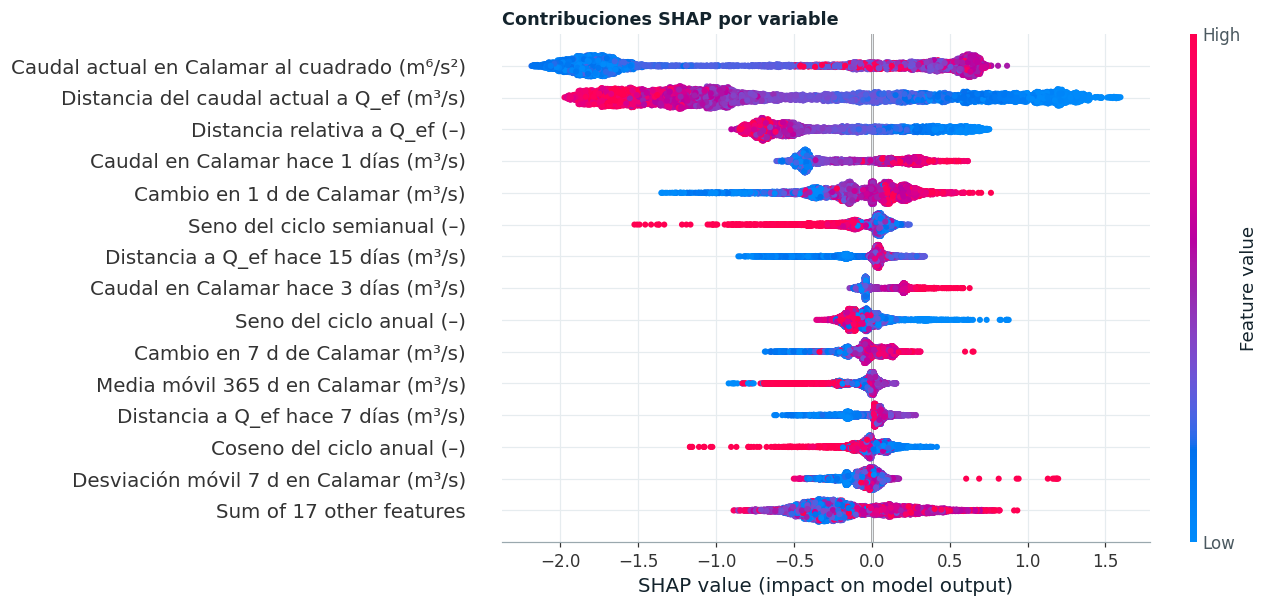

In [2]:
shap.plots.beeswarm(sv, max_display=15, show=False, plot_size=(9.5, 6))
plt.title("Contribuciones SHAP por variable", loc="left", fontweight="bold"); plt.show()
imp = pd.Series(np.abs(sv.values).mean(0), index=Xte.columns).sort_values(ascending=False)
glue("shap_top1", etiqueta(imp.index[0]), display=False); glue("shap_top2", etiqueta(imp.index[1]), display=False)
glue("shap_top3", etiqueta(imp.index[2]), display=False)
glue("shap_frac_top5", float(imp.head(5).sum() / imp.sum()), display=False)
est_aguas_arriba = imp[[c for c in imp.index if not c.startswith(("calamar", "dist", "sen", "cos"))]].sum() / imp.sum()
glue("shap_frac_arriba", float(est_aguas_arriba), display=False)
tc = imp[[c for c in imp.index if c.startswith(("tres_cruces", "coyongal"))]].sum() / imp.sum()
glue("shap_frac_deriva", float(tc), display=False)

Las tres variables con mayor contribución media son «{glue:text}`shap_top1`»,
«{glue:text}`shap_top2`» y «{glue:text}`shap_top3`», y las cinco primeras concentran el
{glue:text}`shap_frac_top5:.0%` de la importancia total. El patrón de colores describe la regla
física que el modelo aprendió: una distancia grande a la descarga efectiva (rojo en la segunda
fila) empuja la predicción hacia fuera de la banda, mientras que una distancia pequeña la empuja
hacia dentro; el caudal actual al cuadrado actúa en el mismo sentido, con contribuciones
negativas para los caudales bajos. El cambio diario del caudal y el rezago de un día aportan la
tendencia de corto plazo: un río que sube se acerca a la banda desde abajo. Los armónicos
estacionales contribuyen con signo coherente con el régimen bimodal. Puerto Salgar, en cambio,
aporta apenas el {glue:text}`shap_frac_arriba:.1%` de la importancia: con un horizonte de quince
días y un tránsito de veintiuno, su señal anticipada existe pero queda en buena parte contenida en
el estado reciente de Calamar, lo que confirma lo observado en la comparación de diseños del
capítulo 2.

## Interpretabilidad local

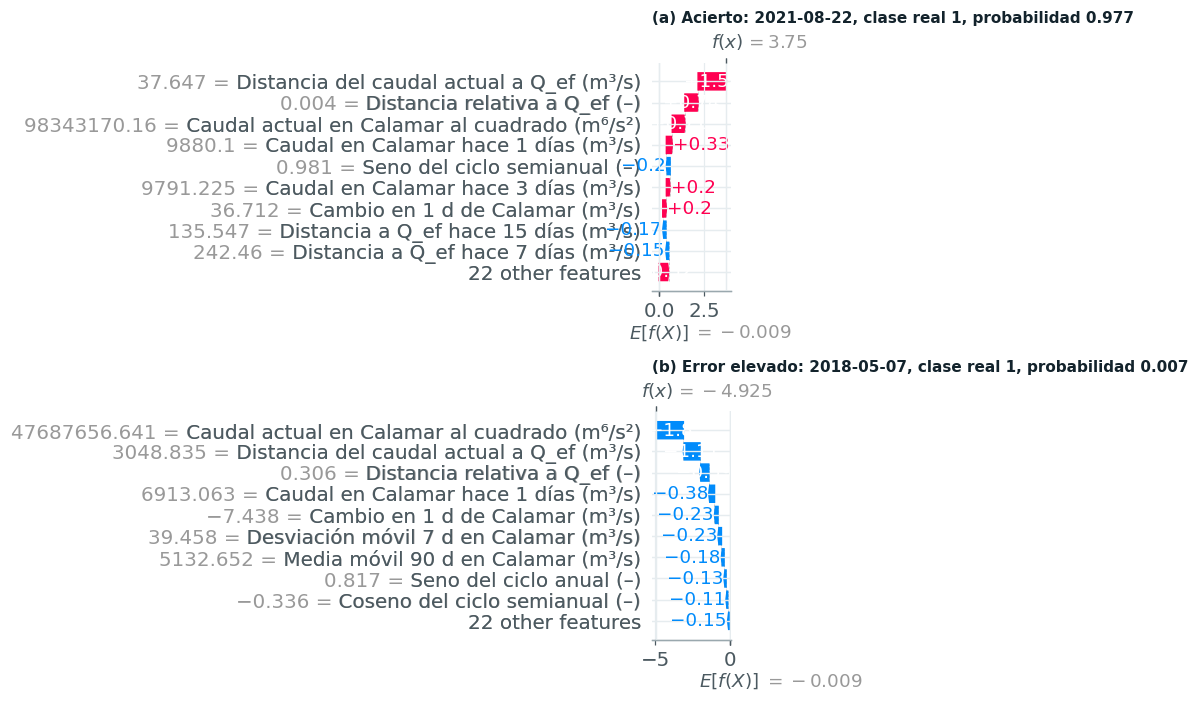

In [3]:
p = fin[M]["pred_test"]; y = D.y_clf_test.values
err = np.abs(y - p)
i_ok = int(np.argmax(np.where((y == 1) & (p > .5), p, -1)))
i_mal = int(np.argmax(err))
fig = plt.figure(figsize=(10, 9))
for k, (i, tit) in enumerate(((i_ok, "(a) Acierto"), (i_mal, "(b) Error elevado"))):
    ax = fig.add_subplot(2, 1, k + 1); plt.sca(ax)
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    ax.set_title(f"{tit}: {D.fechas_test.iloc[i]:%Y-%m-%d}, clase real {y[i]}, probabilidad {p[i]:.3f}", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
for nombre, i in (("ok", i_ok), ("mal", i_mal)):
    glue(f"fecha_{nombre}", f"{D.fechas_test.iloc[i]:%Y-%m-%d}", display=False)
    glue(f"p_{nombre}", float(p[i]), display=False); glue(f"y_{nombre}", int(y[i]), display=False)
    top = pd.Series(sv.values[i], index=Xte.columns).abs().sort_values(ascending=False).index[:3]
    glue(f"top_{nombre}", "; ".join(etiqueta(c) for c in top), display=False)
q_mal = D.y_reg_test.values[i_mal]; q_hoy = np.sqrt(Xte.calamar_cuad.iloc[i_mal])
glue("q_mal", float(q_mal), display=False); glue("q_hoy_mal", float(q_hoy), display=False)

El acierto ({glue:text}`fecha_ok`, probabilidad {glue:text}`p_ok:.3f`) es un día en que el caudal
ya estaba cerca de la descarga efectiva; las contribuciones dominantes son
«{glue:text}`top_ok`», y todas empujan en el mismo sentido. El error elevado
({glue:text}`fecha_mal`) es más instructivo: el modelo asignó una probabilidad de
{glue:text}`p_mal:.3f` a un día que sí estuvo en la banda. El caudal de ese día era de
{glue:text}`q_hoy_mal:,.0f` m³/s y quince días después alcanzó {glue:text}`q_mal:,.0f` m³/s, apenas
por encima del límite inferior de la banda (8.461 m³/s). Las variables que explican el error
(«{glue:text}`top_mal`») describen un río todavía lejos de la banda, y el modelo no tenía cómo
anticipar un ascenso de más de 1.500 m³/s en quince días que lo dejaría en el borde. Es un tipo
de error característico de un objetivo definido por umbrales: los días que cruzan el límite por
un margen pequeño, donde la etiqueta binaria trata igual un caudal de 8.500 m³/s que uno de
10.000 m³/s. La observación sugiere que un modelo que estime cuán lejos de los límites quedará
el caudal, y no solo de qué lado, podría reducir este tipo de error.

## Comparación con LIME

In [4]:
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import spearmanr
Xtr = D.X.fillna(D.X.median())
lime_exp = LimeTabularExplainer(Xtr.values, feature_names=list(Xte.columns), class_names=["fuera", "en banda"],
                                discretize_continuous=True, random_state=SEED, mode="classification")
f = lambda Z: np.column_stack([1 - puntaje_continuo(pipe, pd.DataFrame(Z, columns=Xte.columns)),
                               puntaje_continuo(pipe, pd.DataFrame(Z, columns=Xte.columns))])
filas = []
for nombre, i in (("acierto", i_ok), ("error elevado", i_mal)):
    e = lime_exp.explain_instance(Xte.fillna(Xtr.median()).values[i], f, num_features=10, num_samples=3000)
    lime_w = {}
    for idx, w in e.as_map()[1]:
        lime_w[Xte.columns[idx]] = w
    s = pd.Series(sv.values[i], index=Xte.columns)
    comunes = list(lime_w)
    rho = spearmanr([abs(lime_w[c]) for c in comunes], [abs(s[c]) for c in comunes])[0]
    top_shap = set(s.abs().sort_values(ascending=False).index[:10])
    filas.append({"observación": nombre, "R² del sustituto local de LIME": e.score,
                  "variables comunes en el top 10": len(top_shap & set(lime_w)),
                  "Spearman |LIME| vs |SHAP| (top 10 LIME)": rho,
                  "signos coincidentes": int(sum(np.sign(lime_w[c]) == np.sign(s[c]) for c in comunes)),
                  "top 3 LIME": "; ".join(e.as_list()[k][0] for k in range(3))})
cmp = pd.DataFrame(filas)
for r in cmp.itertuples():
    k = "ok" if r.observación == "acierto" else "mal"
    glue(f"lime_r2_{k}", float(r[2]), display=False); glue(f"lime_comunes_{k}", int(r[3]), display=False)
    glue(f"lime_rho_{k}", float(r[4]), display=False)
cmp.round(3)

,observación,R² del sustituto local de LIME,variables comunes en el top 10,Spearman |LIME| vs |SHAP| (top 10 LIME),signos coincidentes,top 3 LIME
0,acierto,0.452,9,0.891,10,dist_qef <= 1415.54; calamar_cuad > 81812025.0...
1,error elevado,0.144,5,0.952,9,2973.46 < dist_qef <= 4669.46; 28249225.00 < c...


In [5]:
# Concordancia SHAP-LIME en una muestra de 100 días de prueba próximos a un límite de la banda
# (a menos del 5 % de Q_ef) y 100 días alejados (a más del 20 %)
import json
from scipy.stats import mannwhitneyu
from src.config import DATOS_PROC
par = json.loads((DATOS_PROC / "parametros.json").read_text(encoding="utf-8"))["calamar"]
yq = D.y_reg_test.values
d_lim = np.minimum(np.abs(yq - par["LIM"][0]), np.abs(yq - par["LIM"][1])) / par["Q_EF"]
rng = np.random.default_rng(SEED)
grupos = {"próximos al límite": rng.choice(np.flatnonzero(d_lim < .05), 100, replace=False),
          "alejados del límite": rng.choice(np.flatnonzero(d_lim > .20), 100, replace=False)}
Xf = Xte.fillna(Xtr.median()).values
muestra = []
for g, ids in grupos.items():
    for i in ids:
        e = lime_exp.explain_instance(Xf[i], f, num_features=10, num_samples=3000)
        lw = {Xte.columns[k]: w for k, w in e.as_map()[1]}
        s = pd.Series(sv.values[i], index=Xte.columns)
        muestra.append({"grupo": g, "R² del sustituto": e.score,
                        "variables comunes (top 10)": len(set(s.abs().sort_values(ascending=False).index[:10]) & set(lw)),
                        "Spearman |LIME| vs |SHAP|": spearmanr([abs(lw[c]) for c in lw], [abs(s[c]) for c in lw])[0],
                        "signos coincidentes": np.mean([np.sign(lw[c]) == np.sign(s[c]) for c in lw])})
muestra = pd.DataFrame(muestra)
tab_m = muestra.groupby("grupo").median().T
tab_m["p (Mann-Whitney)"] = [mannwhitneyu(muestra.loc[muestra.grupo == "próximos al límite", c].dropna(),
                                          muestra.loc[muestra.grupo == "alejados del límite", c].dropna()).pvalue
                             for c in tab_m.index]
for c, k in (("Spearman |LIME| vs |SHAP|", "rho"), ("signos coincidentes", "sig"), ("R² del sustituto", "r2"),
             ("variables comunes (top 10)", "com")):
    glue(f"m_{k}_borde", float(tab_m.loc[c, "próximos al límite"]), display=False)
    glue(f"m_{k}_lejos", float(tab_m.loc[c, "alejados del límite"]), display=False)
    glue(f"m_{k}_p", float(tab_m.loc[c, "p (Mann-Whitney)"]), display=False)
tab_m.round(3)

grupo,alejados del límite,próximos al límite,p (Mann-Whitney)
R² del sustituto,0.242,0.336,0.117
variables comunes (top 10),7.000,7.000,0.785
Spearman |LIME| vs |SHAP|,0.758,0.733,0.357
signos coincidentes,1.000,0.900,0.001


LIME {cite}`ribeiro2016` explica cada predicción ajustando un modelo lineal ponderado a
perturbaciones de la observación en un entorno local, mientras que SHAP distribuye la predicción
entre las variables según los valores de Shapley, que cumplen eficiencia (la suma de las
contribuciones es exactamente la diferencia entre la predicción y el valor esperado), simetría y
aditividad. En el día acertado ambos métodos coinciden: comparten {glue:text}`lime_comunes_ok` de
las diez variables más importantes y la correlación de rangos entre sus magnitudes es
{glue:text}`lime_rho_ok:.2f`, aunque el sustituto lineal de LIME solo explica un
R² = {glue:text}`lime_r2_ok:.2f` del modelo en el entorno. En el día con error, la coincidencia
cae a {glue:text}`lime_comunes_mal` variables comunes y el R² del sustituto local a
{glue:text}`lime_r2_mal:.2f`.

Dos observaciones no bastan para establecer un patrón, por lo que la comparación se extendió a una
muestra de cien días de prueba próximos a un límite de la banda y cien alejados de él (tabla
anterior). La muestra matiza lo observado en los dos días. La correlación de rangos entre las
magnitudes de LIME y SHAP es similar en ambos grupos ({glue:text}`m_rho_borde:.2f` en los días
próximos y {glue:text}`m_rho_lejos:.2f` en los alejados, medianas; p = {glue:text}`m_rho_p:.2f`,
Mann-Whitney), el R² del sustituto local tampoco difiere (p = {glue:text}`m_r2_p:.2f`) y ambos
métodos coinciden en una mediana de {glue:text}`m_com_borde:.0f` de las diez variables más
relevantes. La caída del R² en el día con error no es, por tanto, una propiedad general de los
días próximos al límite. La diferencia sistemática está en el signo: la proporción de variables a
las que ambos métodos asignan el mismo sentido de contribución es de
{glue:text}`m_sig_lejos:.2f` en los días alejados y baja a {glue:text}`m_sig_borde:.2f` en los
próximos (p = {glue:text}`m_sig_p:.3f`). Cerca de un límite, LIME invierte el sentido de alguna de
las variables secundarias, aunque identifica bien cuáles son relevantes y en qué orden.

La inversión de signos tiene dos causas. Cerca de un límite, la probabilidad predicha cambia
bruscamente con el caudal, y una aproximación lineal ajustada a perturbaciones del entorno
promedia contribuciones de ambos lados del límite, que tienen signo opuesto, mientras que TreeSHAP calcula las
contribuciones exactas del modelo de árboles sin aproximarlo. Además, LIME discretiza las
variables continuas en cuartiles y perturba cada una de forma independiente, lo que genera
combinaciones poco plausibles cuando las variables están tan correlacionadas como los rezagos de un
caudal con autocorrelación de 0,999. Cabe esperar, por tanto, que ambas técnicas diverjan cuando
el modelo es fuertemente no lineal en el entorno de la observación, cuando las variables están
correlacionadas y cuando la observación está cerca de una frontera de decisión. En esos casos la
explicación de SHAP es la más fiel al modelo, y la de LIME debe leerse en cuanto a las
variables que identifica y su importancia relativa, pero no en cuanto al sentido de las
contribuciones secundarias.